# MyDeZero GPU Optimization

## Fused FP32 Adam

The standard CUDA Adam path launches separate array operations for the moments,
bias correction, and weight update. This adds launch overhead and intermediate
reads and writes. MyDeZero's fused update uses one CuPy CUDA kernel per eligible
parameter tensor to update the weights and both moments in place. It keeps the
existing bias correction and uses the standard path for unsupported layouts,
dtypes, or overlapping buffers. `Adam(fused=False)` selects the reference path.

Install MyDeZero and use a kernel with CuPy and a CUDA device. See the
[CuPy setup guide](../../doc/cupy-setup.md). This experiment uses synthetic data.

## Revision scope

The initial-stage tables below were produced before the large-model corrections.
The final **Large-model follow-up** section is the acceptance record for the
updated framework. It separates original behavior, corrected FP32 arithmetic,
flattened pointwise GEMM and experimental cuDNN. The earlier cuDNN probe used
the allow-conversion math constant instead of FMA math. Its initial timings
cannot support strict-FP32 claims. The new backend requests `CUDNN_FMA_MATH`
and the follow-up processes explicitly disable TF32.


In [1]:
import platform
from statistics import median
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np

from mydezero import Model, cuda
import mydezero.functions as F
import mydezero.layers as L
from mydezero.optimizers import Adam

BATCHES = (1, 16, 64)
ROUNDS = 7
CALLS_PER_ROUND = 15
BATCH_SIZE = max(BATCHES)
rng = np.random.default_rng(42)
inputs = rng.standard_normal((BATCH_SIZE, 64), dtype=np.float32)
labels = rng.integers(0, 8, BATCH_SIZE, dtype=np.int64)
shapes = ((64, 128), (128, 128), (128, 128), (128, 8))
weights = [rng.standard_normal(shape, dtype=np.float32) * np.float32(0.1) for shape in shapes]

print(f"{platform.system()} / Python {platform.python_version()} / NumPy {np.__version__}")
if not cuda.gpu_enable or cuda.cupy.cuda.runtime.getDeviceCount() == 0:
    raise RuntimeError('Run this notebook in a kernel with CuPy and a CUDA device.')
cp = cuda.cupy
device = cp.cuda.runtime.getDeviceProperties(cp.cuda.Device().id)['name'].decode()
print(f'{device} / CuPy {cp.__version__}')

Windows / Python 3.9.25 / NumPy 2.0.2
NVIDIA GeForce RTX 5060 Laptop GPU / CuPy 13.6.0


In [2]:
class MLP(Model):
    def __init__(self, xp):
        super().__init__()
        self.fc1 = L.Linear(128, in_size=64)
        self.fc2 = L.Linear(128, in_size=128)
        self.fc3 = L.Linear(128, in_size=128)
        self.fc4 = L.Linear(8, in_size=128)
        for layer, weight in zip((self.fc1, self.fc2, self.fc3, self.fc4), weights):
            layer.W.data = xp.asarray(weight).copy()
            layer.b.data = xp.zeros(weight.shape[1], dtype=xp.float32)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        return self.fc4(x)

    def ordered_parameters(self):
        return [param for layer in (self.fc1, self.fc2, self.fc3, self.fc4)
                for param in (layer.W, layer.b)]


def make_trial(xp, fused):
    model = MLP(xp)
    return model, Adam(lr=0.003, fused=fused).setup(model)


def step(trial, x, y):
    model, optimizer = trial
    model.cleargrads()
    loss = F.softmax_cross_entropy(model(x), y)
    loss.backward()
    optimizer.update()
    return loss.data


def verify_updates(xp, x, y):
    standard_model, standard = make_trial(xp, fused=False)
    fused_model, fused = make_trial(xp, fused=True)
    for _ in range(12):
        left = step((standard_model, standard), x, y)
        right = step((fused_model, fused), x, y)
        np.testing.assert_allclose(cuda.as_numpy(left), cuda.as_numpy(right), rtol=2e-5, atol=2e-6)
        for a, b in zip(standard_model.ordered_parameters(), fused_model.ordered_parameters()):
            first, second = id(a), id(b)
            assert standard.ts[first] == fused.ts[second]
            for actual, expected in (
                (b.data, a.data), (b.grad.data, a.grad.data),
                (fused.ms[second], standard.ms[first]), (fused.vs[second], standard.vs[first]),
            ):
                assert actual.dtype == expected.dtype == xp.float32
                np.testing.assert_allclose(cuda.as_numpy(actual), cuda.as_numpy(expected),
                                           rtol=2e-5, atol=2e-6)
    print(f"{xp.__name__}: loss, gradients, weights, moments, and step counts matched over 12 updates.")

## Timing and numerical checks

Use the same FP32 arrays, initial values, batches, and Adam settings. First
compare twelve successive updates at each batch size, including losses,
gradients, weights, moments, and step counts. Measure the Adam update alone
with fixed resident gradients, then measure the full MLP training step at
batch sizes 1, 16, and 64. Warm-up includes the first-use CUDA compilation.

Rotate between paths over seven rounds of fifteen calls. Synchronize the
device after each call so wall time includes completion. The timed scope
excludes data transfers. P50 is the median of round medians and P95 is
computed over individual calls.

In [3]:
def measure(run, x, y):
    trials = [make_trial(cp, fused) for fused in (False, True)]
    for trial in trials:
        for _ in range(6):
            step(trial, x, y)
    cp.cuda.runtime.deviceSynchronize()
    times = [[], []]
    for r in range(ROUNDS):
        current = [[], []]
        for j in range(CALLS_PER_ROUND):
            for i in ((0, 1) if (r + j) % 2 == 0 else (1, 0)):
                started = perf_counter()
                run(trials[i])
                cp.cuda.runtime.deviceSynchronize()
                current[i].append((perf_counter() - started) * 1000)
        for group, sample in zip(times, current):
            group.append(sample)
    return [(median(median(row) for row in group), np.percentile(np.concatenate(group), 95))
            for group in times]


x, y = cp.asarray(inputs), cp.asarray(labels)
results = {}
for size in BATCHES:
    bx, by = x[:size], y[:size]
    print(f'Batch {size}', flush=True)
    verify_updates(cp, bx, by)
    results[f'Train b{size}'] = measure(lambda trial: step(trial, bx, by), bx, by)
results['Adam update'] = measure(lambda trial: trial[1].update(), x, y)

Batch 1
cupy: loss, gradients, weights, moments, and step counts matched over 12 updates.
Batch 16
cupy: loss, gradients, weights, moments, and step counts matched over 12 updates.
Batch 64
cupy: loss, gradients, weights, moments, and step counts matched over 12 updates.


Standard → fused. Values are P50 / P95 in ms.
Adam update  1.052 / 1.426 → 0.174 / 0.291   (6.03× P50 speedup)
Train b1     3.803 / 5.189 → 1.976 / 2.433   (1.92× P50 speedup)
Train b16    3.946 / 5.015 → 2.034 / 2.795   (1.94× P50 speedup)
Train b64    2.205 / 3.448 → 1.152 / 1.916   (1.91× P50 speedup)


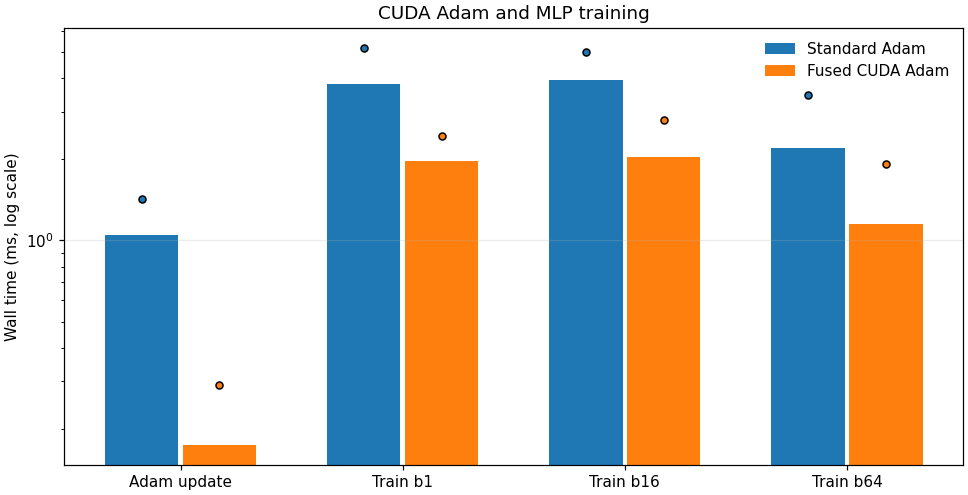

In [4]:
names = ('Adam update', *(f'Train b{size}' for size in BATCHES))
positions = np.arange(len(names))
fig, ax = plt.subplots(figsize=(8.8, 4.5), layout='constrained')
for index, label in enumerate(('Standard Adam', 'Fused CUDA Adam')):
    p50, p95 = np.array([results[name][index] for name in names]).T
    centers = positions + (index - 0.5) * 0.35
    bars = ax.bar(centers, p50, 0.33, label=label)
    ax.scatter(centers, p95, color=bars[0].get_facecolor(), edgecolor='black', s=21)
ax.set(title='CUDA Adam and MLP training', ylabel='Wall time (ms, log scale)', yscale='log')
ax.set_xticks(positions, names)
ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.25)
plt.show()

print('Standard → fused. Values are P50 / P95 in ms.')
for name in names:
    (old_50, old_95), (new_50, new_95) = results[name]
    print(f'{name:<12} {old_50:.3f} / {old_95:.3f} → {new_50:.3f} / {new_95:.3f}'
          f'   ({old_50 / new_50:.2f}× P50 speedup)')

Bars show P50 and dots show P95. The optimizer-only result isolates launches
and array operations. Full training also includes pre-existing forward and
backward kernels, so its speedup depends on the fraction of time spent in Adam.
These timings cover the tested hardware, FP32 MLP, and batch sizes.

## Stage 1 · Profiling, pointwise convolution and direct pooling

Use the same Toy, Iris and MNIST model definitions across the original and
optimized GPU paths. Every CNN includes a pointwise projection. All initialized
weights are explicitly FP32, so this comparison isolates GPU implementation.
Install scikit-learn, threadpoolctl and CUDA-enabled PyTorch for this section.
The official MNIST subsets contain 1,200 training and 500 held-out images.

The operator benchmark reports synchronized wall P50/P95, CUDA Event elapsed
P50 and CPU enqueue P50. The complete-model ablation rotates variants. Data
transfers and correctness checks occur outside resident-data timings.

In [5]:
from contextlib import contextmanager, nullcontext
from dataclasses import dataclass
from itertools import product
from unittest.mock import patch
from pathlib import Path
import importlib.util
import shutil
import sys

from sklearn.datasets import load_iris
from sklearn.metrics import precision_recall_fscore_support
from threadpoolctl import threadpool_limits
import torch
from torch import nn

from mydezero import Variable, Layer, Parameter, no_grad, test_mode
from mydezero.datasets import MNIST
from mydezero.models import MLP
import mydezero.functions_conv as FC

torch.set_num_threads(1)
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
BATCHES = (1, 16, 64)
SEEDS = (42, 43, 44, 45, 46)
RUNS, ROUNDS, CALLS = 3, 7, 12
print(f'PyTorch {torch.__version__}, CUDA {cp.cuda.runtime.runtimeGetVersion()}')
print('nsys:', shutil.which('nsys'), '| ncu:', shutil.which('ncu'))


def measure(calls):
    history = [[] for _ in calls]
    for context, call in calls:
        with context():
            for _ in range(6):
                call()
    cp.cuda.runtime.deviceSynchronize()
    start_event, end_event = cp.cuda.Event(), cp.cuda.Event()
    for run in range(RUNS):
        for r in range(ROUNDS):
            rows = [[] for _ in calls]
            for j in range(CALLS):
                for k in range(len(calls)):
                    i = (run + r + j + k) % len(calls)
                    context, call = calls[i]
                    with context():
                        cp.cuda.runtime.deviceSynchronize()
                        begin = perf_counter()
                        start_event.record()
                        call()
                        submitted = perf_counter()
                        end_event.record()
                        cp.cuda.runtime.deviceSynchronize()
                        end = perf_counter()
                        rows[i].append(((end - begin) * 1000,
                                        cp.cuda.get_elapsed_time(start_event, end_event),
                                        (submitted - begin) * 1000))
            for values, row in zip(history, rows):
                values.append(row)
    result = []
    for values in history:
        samples = np.array(values)
        p50 = np.median(np.median(samples, axis=1), axis=0)
        result.append(dict(wall=float(p50[0]), gpu=float(p50[1]), submit=float(p50[2]),
                           p95=float(np.percentile(samples[:, :, 0], 95)),
                           rounds=np.median(samples[:, :, 0], axis=1).tolist()))
    return result


def memory_peak(call):
    cp.cuda.runtime.deviceSynchronize()
    pool = cp.cuda.MemoryPool()
    with cp.cuda.using_allocator(pool.malloc):
        result = call()
        cp.cuda.runtime.deviceSynchronize()
        retained = pool.total_bytes()
        live = pool.used_bytes()
        del result
    return dict(retained_kib=retained / 1024, output_live_kib=live / 1024)


pointwise_dispatch = FC._gpu_pointwise
pooling_forward = FC.Pooling.forward
loss_forward = F.SoftmaxCrossEntropy.forward


def reference_pool(self, x):
    self.direct_gpu = False
    col = FC.im2col_array(x, self.kernel_size, self.stride, self.pad, to_matrix=False)
    n, c, kh, kw, oh, ow = col.shape
    col = col.reshape(n, c, kh * kw, oh, ow)
    self.indexes = col.argmax(axis=2)
    return col.max(axis=2)


def reference_loss(self, x, t):
    self.gpu_probabilities = None
    shifted = x - x.max(axis=1, keepdims=True)
    log_p = shifted - F.utils.logsumexp(shifted, axis=1)
    return -log_p[np.arange(x.shape[0]), t.ravel()].mean()


@contextmanager
def enabled(features):
    point = pointwise_dispatch if 'Point' in features else lambda *_: False
    pool = pooling_forward if 'Pool' in features else reference_pool
    loss = loss_forward if 'Loss' in features else reference_loss
    with patch.object(FC, '_gpu_pointwise', point), patch.object(FC.Pooling, 'forward', pool), \
            patch.object(F.SoftmaxCrossEntropy, 'forward', loss):
        yield


FEATURES = ('Adam', 'Point', 'Pool', 'Loss')
BASE, ALL = frozenset(), frozenset(FEATURES)
VARIANTS = [BASE, frozenset(('Adam',))]
for feature in FEATURES[1:]:
    VARIANTS.extend((frozenset((feature,)), frozenset(('Adam', feature))))
VARIANTS.extend((ALL, *(ALL - {feature} for feature in FEATURES)))
VARIANTS = list(dict.fromkeys(VARIANTS))


def label(features):
    return '+'.join(f for f in FEATURES if f in features) or 'Original'
rand = np.random.default_rng(7)


PyTorch 2.8.0+cu128, CUDA 12090
nsys: None | ncu: C:\Program Files\NVIDIA Corporation\Nsight Compute 2021.1.0\ncu.BAT


In [6]:
@dataclass(frozen=True)
class Workload:
    name: str
    train: tuple
    test: tuple
    channels: tuple
    kernels: tuple
    hidden: tuple
    classes: int
    epochs: int
    training_batch: int

    @property
    def flattened(self):
        size = self.train[0].shape[-1]
        for kernel in self.kernels:
            size = (size - kernel + 1) // 2
        return self.channels[-1] * size * size


def toy_data(per_class, rng):
    patterns = np.zeros((3, 1, 8, 8), dtype=np.float32)
    patterns[0, 0, :, 1:3] = 1
    patterns[1, 0, 1:3, :] = 1
    patterns[2, 0, 4:7, 4:7] = 1
    y = rng.permutation(np.repeat(np.arange(3), per_class))
    x = patterns[y] + np.float32(0.25) * rng.standard_normal((len(y), 1, 8, 8), dtype=np.float32)
    return x, y


def iris_data():
    iris = load_iris()
    rng = np.random.default_rng(42)
    classes = [rng.permutation(np.flatnonzero(iris.target == k)) for k in range(3)]
    train = rng.permutation(np.concatenate([ids[:40] for ids in classes]))
    test = rng.permutation(np.concatenate([ids[40:] for ids in classes]))
    values = iris.data.astype(np.float32)
    x = (values - values[train].mean(axis=0)) / values[train].std(axis=0)
    x = x.reshape(-1, 1, 2, 2).repeat(16, axis=2).repeat(16, axis=3)
    return (x[train], iris.target[train]), (x[test], iris.target[test])


def mnist_split(train, per_class):
    ds = MNIST(train=train)
    rng = np.random.default_rng(42 if train else 43)
    classes = [rng.choice(np.flatnonzero(ds.label == k), per_class, replace=False)
               for k in range(10)]
    ids = rng.permutation(np.concatenate(classes))
    return ds.data[ids].astype(np.float32) / np.float32(255), ds.label[ids].astype(np.int64)


rng = np.random.default_rng(42)
iris_train, iris_test = iris_data()
workloads = (
    Workload("Toy CNN", toy_data(128, rng), toy_data(64, rng), (4, 8), (3, 2), (16,), 3, 3, 32),
    Workload("Iris LeNet-style", iris_train, iris_test, (6, 16), (5, 5), (120, 84), 3, 8, 15),
    Workload("MNIST CNN", mnist_split(True, 120), mnist_split(False, 50),
             (16, 32), (3, 3), (128, 64), 10, 3, 64),
)

In [7]:
class ReferencePooling(FC.Pooling):
    def forward(self, x):
        col = FC.im2col_array(x, self.kernel_size, self.stride, self.pad, to_matrix=False)
        n, c, kh, kw, oh, ow = col.shape
        col = col.reshape(n, c, kh * kw, oh, ow)
        self.indexes = col.argmax(axis=2)
        return col.max(axis=2)


class CNN(Model):
    def __init__(self, data):
        super().__init__()
        c1, c2 = data.channels
        k1, k2 = data.kernels
        self.conv1 = L.Conv2d(c1, k1, in_channels=1)
        self.projection = L.Conv2d(c1, 1, in_channels=c1)
        self.conv2 = L.Conv2d(c2, k2, in_channels=c1)
        self.head = MLP(data.hidden + (data.classes,), activation=F.relu)
        self.layers = (self.conv1, self.projection, self.conv2, *self.head.layers)

    def forward(self, x):
        x = F.pooling(F.relu(self.conv1(x)), 2, stride=2)
        x = F.relu(self.projection(x))
        x = F.pooling(F.relu(self.conv2(x)), 2, stride=2)
        return self.head(x.reshape(x.shape[0], -1))


class TorchCNN(nn.Module):
    def __init__(self, data, my_model):
        super().__init__()
        c1, c2 = data.channels
        k1, k2 = data.kernels
        self.conv1 = nn.Conv2d(1, c1, k1)
        self.projection = nn.Conv2d(c1, c1, 1)
        self.conv2 = nn.Conv2d(c1, c2, k2)
        sizes = (data.flattened, *data.hidden, data.classes)
        self.head = nn.ModuleList(nn.Linear(i, j) for i, j in zip(sizes, sizes[1:]))
        with torch.no_grad():
            for module, source in zip((self.conv1, self.projection, self.conv2, *self.head), my_model.layers):
                w = cp.asnumpy(source.W.data)
                module.weight.copy_(torch.from_numpy(w.T if w.ndim == 2 else w))
                module.bias.copy_(torch.from_numpy(cp.asnumpy(source.b.data)))
        self.eval()

    def forward(self, x):
        x = nn.functional.max_pool2d(self.conv1(x).relu(), 2)
        x = self.projection(x).relu()
        x = nn.functional.max_pool2d(self.conv2(x).relu(), 2).flatten(1)
        for layer in self.head[:-1]:
            x = layer(x).relu()
        return self.head[-1](x)


def make_model(data, seed, weight_dtype=np.float32):
    model = CNN(data)
    with no_grad():
        model(data.train[0][:1])
    rng = np.random.default_rng(seed)
    for layer in model.layers:
        shape = layer.W.shape
        fan_in = shape[0] if len(shape) == 2 else np.prod(shape[1:])
        weights = rng.standard_normal(shape, dtype=np.float32) * np.float32(np.sqrt(2 / fan_in))
        layer.W.data = weights.astype(weight_dtype, copy=False)
        layer.b.data = np.zeros_like(layer.b.data, dtype=np.float32)
    model.to_gpu()
    return model


def step(model, optimizer, batch):
    model.cleargrads()
    loss = F.softmax_cross_entropy(model(batch[0]), batch[1])
    loss.backward()
    optimizer.update()
    return loss.data

Phase measurements include synchronization and do not sum to the whole-step time.
Toy CNN {'Forward': 1.064, 'Loss': 0.261, 'Backward': 1.752, 'Adam': 1.334, 'Whole step': 4.368}
Iris LeNet-style {'Forward': 0.687, 'Loss': 0.274, 'Backward': 1.842, 'Adam': 1.674, 'Whole step': 4.858}
MNIST CNN {'Forward': 0.741, 'Loss': 0.264, 'Backward': 2.29, 'Adam': 1.644, 'Whole step': 5.006}


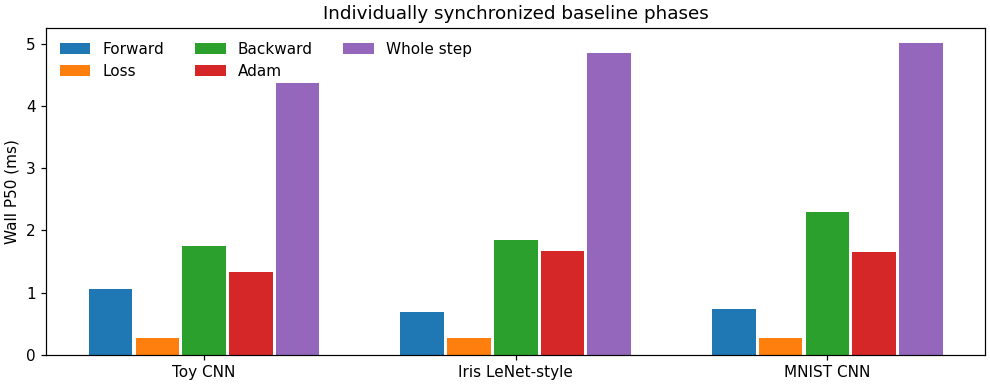

In [8]:
def phase_breakdown(data):
    model = make_model(data, 42)
    opt = Adam(fused=False).setup(model)
    x, y = (cp.asarray(a[:data.training_batch]) for a in data.train)
    model.cleargrads()
    with enabled(BASE):
        logits = model(x)
        loss = F.softmax_cross_entropy(logits, y)
    phases = {
        'Forward': lambda: model(x),
        'Loss': lambda: F.softmax_cross_entropy(logits, y),
        'Backward': lambda: (model.cleargrads(), loss.backward()),
    }
    with enabled(BASE):
        measurements = {name: measure([(nullcontext, call)])[0] for name, call in phases.items()}
        step(model, opt, (x, y))
        measurements['Adam'] = measure([(nullcontext, opt.update)])[0]
        measurements['Whole step'] = measure([(nullcontext, lambda: step(model, opt, (x, y)))])[0]
    return measurements


breakdown = {data.name: phase_breakdown(data) for data in workloads}
fig, ax = plt.subplots(figsize=(9, 3.5), layout='constrained')
for j, phase in enumerate(('Forward', 'Loss', 'Backward', 'Adam', 'Whole step')):
    positions = np.arange(len(workloads)) + (j - 2) * 0.15
    ax.bar(positions, [breakdown[d.name][phase]['wall'] for d in workloads], 0.14, label=phase)
ax.set_xticks(np.arange(len(workloads)), [d.name for d in workloads])
ax.set(ylabel='Wall P50 (ms)', title='Individually synchronized baseline phases')
ax.legend(frameon=False, ncol=3)
plt.show()
print('Phase measurements include synchronization and do not sum to the whole-step time.')
for name, phases in breakdown.items():
    print(name, {key: round(value['wall'], 3) for key, value in phases.items()})

('Pointwise', 'Forward') wall P50/P95 0.193/0.393 → 0.184/0.398 device/submit 0.171/0.158 [{'retained_kib': 9408.0, 'output_live_kib': 3136.0}, {'retained_kib': 6289.5, 'output_live_kib': 3136.0}]
('Pointwise', 'dX') wall P50/P95 0.219/0.421 → 0.185/0.389 device/submit 0.174/0.149 [{'retained_kib': 6272.0, 'output_live_kib': 3136.0}, {'retained_kib': 3153.5, 'output_live_kib': 3136.0}]
('Pointwise', 'dW') wall P50/P95 0.216/0.364 → 0.137/0.263 device/submit 0.124/0.076 [{'retained_kib': 9424.0, 'output_live_kib': 16.0}, {'retained_kib': 6288.0, 'output_live_kib': 16.0}]
('Pointwise wide', 'Forward') wall P50/P95 0.266/0.365 → 0.222/0.369 device/submit 0.206/0.124 [{'retained_kib': 14112.0, 'output_live_kib': 1568.0}, {'retained_kib': 7905.5, 'output_live_kib': 1568.0}]
('Pointwise wide', 'dX') wall P50/P95 0.251/0.405 → 0.176/0.330 device/submit 0.163/0.111 [{'retained_kib': 14112.0, 'output_live_kib': 6272.0}, {'retained_kib': 6337.5, 'output_live_kib': 6272.0}]
('Pointwise wide', 'dW

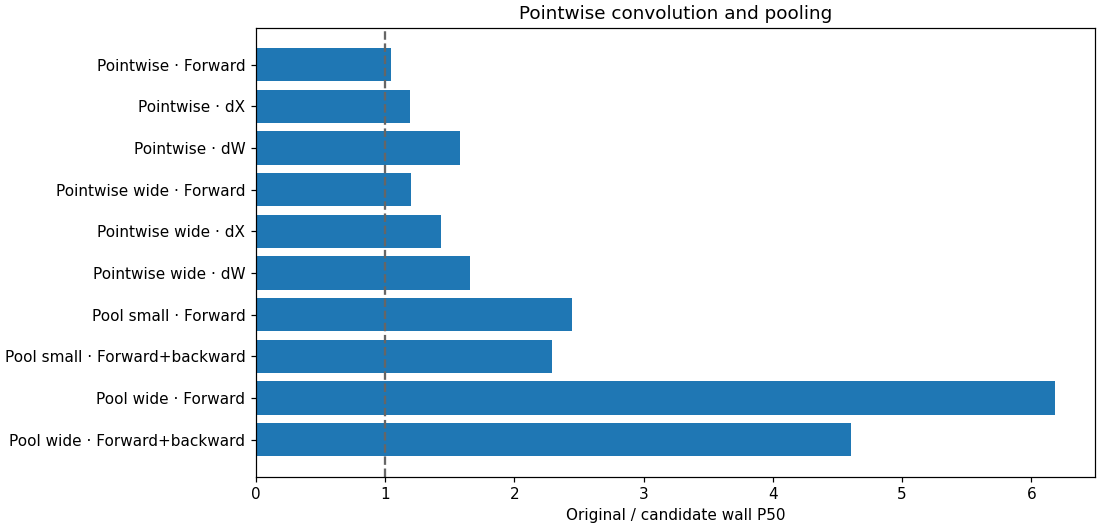

In [9]:
rand = np.random.default_rng(7)
operator_results, allocation_results = {}, {}
fixtures = (
    ('Point', 'Pointwise', (16, 64, 28, 28), (64, 64, 1, 1)),
    ('Point', 'Pointwise wide', (8, 256, 28, 28), (64, 256, 1, 1)),
)
for feature, name, shape, weight_shape in fixtures:
    x = cp.asarray(rand.standard_normal(shape, dtype=np.float32))
    w = cp.asarray(rand.standard_normal(weight_shape, dtype=np.float32))
    y = FC.conv2d(x, w)
    dy = cp.asarray(rand.standard_normal(y.shape, dtype=np.float32))
    gw = FC.Conv2DGradW(y.creator)
    calls = {'Forward': lambda: FC.conv2d(x, w),
             'dX': lambda: FC.deconv2d(dy, w), 'dW': lambda: gw.forward(x, dy)}
    for phase, call in calls.items():
        with enabled(BASE):
            original = call()
        with enabled({feature}):
            optimized = call()
        original = original.data if isinstance(original, Variable) else original
        optimized = optimized.data if isinstance(optimized, Variable) else optimized
        cp.testing.assert_allclose(optimized, original, atol=5e-4, rtol=2e-4)
        pair = [(lambda: enabled(BASE), call), (lambda: enabled({feature}), call)]
        operator_results[name, phase] = measure(pair)
        allocation_results[name, phase] = []
        for context, operation in pair:
            with context():
                allocation_results[name, phase].append(memory_peak(operation))

for name, shape in (('Pool small', (16, 6, 28, 28)), ('Pool wide', (64, 64, 56, 56))):
    x = Variable(cp.asarray(rand.standard_normal(shape, dtype=np.float32)))
    def pool_forward():
        return FC.pooling(x, 2, stride=2)
    def pool_step():
        x.cleargrad()
        pool_forward().sum().backward()
    for phase, call in (('Forward', pool_forward), ('Forward+backward', pool_step)):
        pair = [(lambda: enabled(BASE), call), (lambda: enabled({'Pool'}), call)]
        operator_results[name, phase] = measure(pair)
        allocation_results[name, phase] = []
        for context, operation in pair:
            with context():
                allocation_results[name, phase].append(memory_peak(operation))

fig, ax = plt.subplots(figsize=(10, 4.8), layout='constrained')
names, speeds = [], []
for key, (old, new) in operator_results.items():
    names.append(' · '.join(key))
    speeds.append(old['wall'] / new['wall'])
    print(key, 'wall P50/P95', f"{old['wall']:.3f}/{old['p95']:.3f} → {new['wall']:.3f}/{new['p95']:.3f}",
          'device/submit', f"{new['gpu']:.3f}/{new['submit']:.3f}", allocation_results[key])
ax.barh(names, speeds)
ax.axvline(1, color='0.4', linestyle='--')
ax.set(xlabel='Original / candidate wall P50', title='Pointwise convolution and pooling')
ax.invert_yaxis()
plt.show()

## Stage 2 · Loss fusion and convolution feasibility

The loss path uses a CUDA C row reduction and an elementwise first derivative.
Higher derivatives use the original differentiable softmax path. The optional
cuDNN probe calls the installed library directly on CuPy device buffers. It
reuses descriptors, requests FP32 FMA math and uses zero-workspace algorithm 0.
This is a feasibility comparison of three convolution directions. Backend
selection, autotuning, portable packaging and full-model cuDNN integration
require subsequent acceptance work.

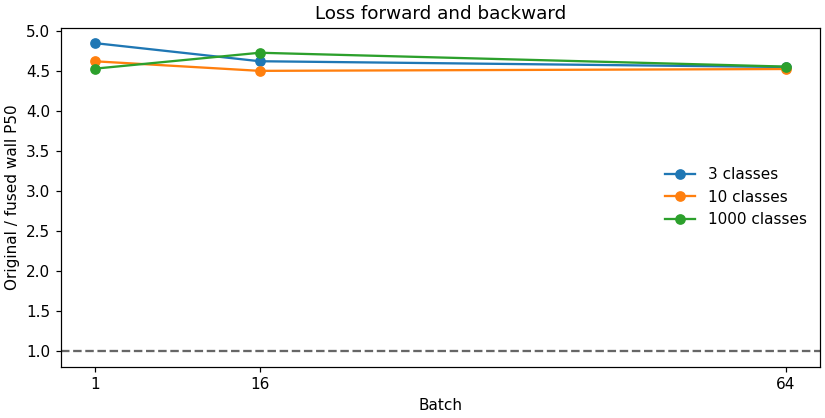

In [10]:
loss_timings = {}
for classes in (3, 10, 1000):
    for batch in BATCHES:
        logits = Variable(cp.asarray(rand.standard_normal((batch, classes), dtype=np.float32)))
        labels = cp.asarray(rand.integers(classes, size=batch, dtype=np.int64))
        def loss_step():
            logits.cleargrad()
            F.softmax_cross_entropy(logits, labels).backward()
        loss_timings[classes, batch] = measure([
            (lambda: enabled(BASE), loss_step), (lambda: enabled({'Loss'}), loss_step)])
fig, ax = plt.subplots(figsize=(7.5, 3.8), layout='constrained')
for classes in (3, 10, 1000):
    ax.plot(BATCHES, [loss_timings[classes, b][0]['wall'] / loss_timings[classes, b][1]['wall']
                      for b in BATCHES], marker='o', label=f'{classes} classes')
ax.axhline(1, color='0.4', linestyle='--')
ax.set(xlabel='Batch', ylabel='Original / fused wall P50', title='Loss forward and backward', xticks=BATCHES)
ax.legend(frameon=False)
plt.show()

LeNet Forward descriptor setup ms 11.526 wall ms [0.215, 0.105] speedup 2.05
LeNet dX descriptor setup ms 11.526 wall ms [0.237, 0.117] speedup 2.03
LeNet dW descriptor setup ms 11.526 wall ms [0.243, 0.124] speedup 1.96
ResNet-style Forward descriptor setup ms 13.266 wall ms [1.047, 0.448] speedup 2.34
ResNet-style dX descriptor setup ms 13.266 wall ms [0.639, 0.558] speedup 1.15
ResNet-style dW descriptor setup ms 13.266 wall ms [1.206, 0.487] speedup 2.47


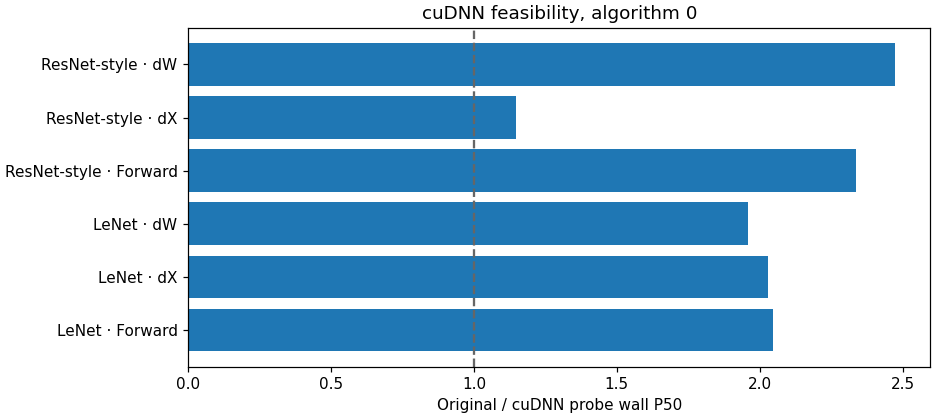

In [11]:
import gpu_cudnn_probe

cudnn_results = {}
try:
    cudnn_library = gpu_cudnn_probe.load_library(torch)
except OSError as error:
    print(f'cuDNN unavailable: {error}')
else:
    for name, shape, wshape, padding in (
        ('LeNet', (16, 6, 14, 14), (16, 6, 5, 5), 0),
        ('ResNet-style', (16, 64, 28, 28), (64, 64, 3, 3), 1),
    ):
        x = cp.asarray(rand.standard_normal(shape, dtype=np.float32))
        w = cp.asarray(rand.standard_normal(wshape, dtype=np.float32))
        reference = FC.conv2d(x, w, pad=padding)
        dy = cp.asarray(rand.standard_normal(reference.shape, dtype=np.float32))
        grad = FC.Conv2DGradW(reference.creator)
        started = perf_counter()
        probe = gpu_cudnn_probe.Convolution(cudnn_library, x, w, pad=padding)
        setup_ms = (perf_counter() - started) * 1000
        try:
            references = {'Forward': lambda: FC.conv2d(x, w, pad=padding).data,
                          'dX': lambda: FC.deconv2d(dy, w, pad=padding, outsize=x.shape[2:]).data,
                          'dW': lambda: grad.forward(x, dy)}
            for direction, original in references.items():
                call = lambda: probe.run(direction, x, w, dy)
                cp.testing.assert_allclose(call(), original(), atol=4e-3, rtol=3e-3)
                values = measure([(nullcontext, original), (nullcontext, call)])
                cudnn_results[name, direction] = values
                print(name, direction, 'descriptor setup ms', round(setup_ms, 3),
                      'wall ms', [round(v['wall'], 3) for v in values],
                      'speedup', round(values[0]['wall'] / values[1]['wall'], 2))
        finally:
            cp.cuda.runtime.deviceSynchronize()
            probe.close()
if cudnn_results:
    fig, ax = plt.subplots(figsize=(8.5, 3.8), layout='constrained')
    ax.barh([' · '.join(k) for k in cudnn_results],
            [v[0]['wall'] / v[1]['wall'] for v in cudnn_results.values()])
    ax.axvline(1, color='0.4', linestyle='--')
    ax.set(xlabel='Original / cuDNN probe wall P50', title='cuDNN feasibility, algorithm 0')
    plt.show()

## Stage 3 · Scheduling, data movement and combined acceptance

Screen fixed-shape CUDA Graph inference and synchronous versus pinned asynchronous
transfer. Capture and buffer preparation are reported separately. The graph
experiment changes input values on each replay and checks the new outputs.
Complete training is measured eagerly because Python Adam counters require a
separate device-state design for correct captured replay.

The final suite contains original, Adam-only, individual operator-only,
Adam-plus-operator, all-on and leave-one-out paths. Each training path starts
with the same parameters and independently evolving Adam state.

Toy CNN original / all-on accuracy, precision, recall, F1 [0.83229167 0.86703823 0.83229167 0.81208446] [0.83229167 0.86703823 0.83229167 0.81208446]
Iris LeNet-style original / all-on accuracy, precision, recall, F1 [0.93333333 0.93427609 0.93333333 0.93323308] [0.93333333 0.93427609 0.93333333 0.93323308]
MNIST CNN original / all-on accuracy, precision, recall, F1 [0.926      0.92979971 0.926      0.92617634] [0.9268     0.93055158 0.9268     0.926947  ]


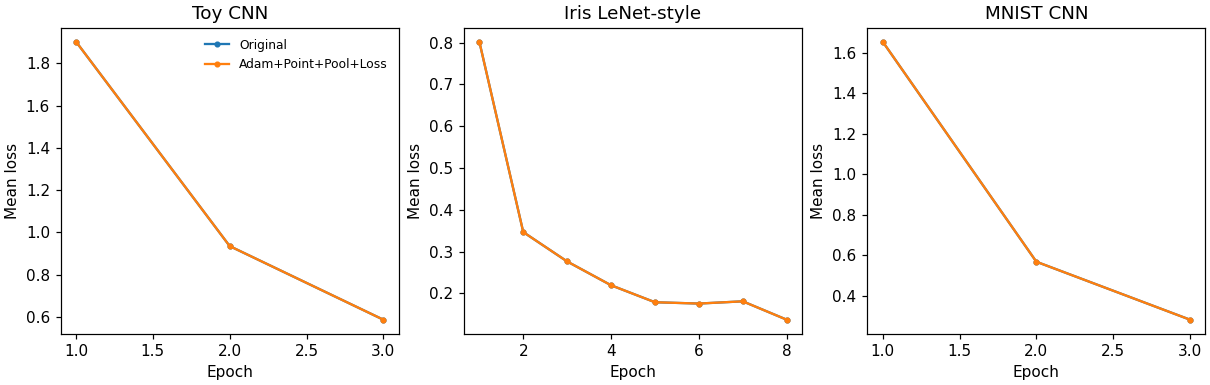

In [12]:
def fit(data, seed, features):
    model = make_model(data, seed)
    optimizer = Adam(lr=0.003, fused='Adam' in features).setup(model)
    x, y = (cp.asarray(a) for a in data.train)
    random = np.random.default_rng(seed)
    curve = []
    with enabled(features):
        for _ in range(data.epochs):
            total = 0.0
            order = random.permutation(len(y))
            for begin in range(0, len(y), data.training_batch):
                ids = cp.asarray(order[begin:begin + data.training_batch])
                value = step(model, optimizer, (x[ids], y[ids]))
                total += float(value) * len(ids)
            curve.append(total / len(y))
    return model, curve


def predict(data, model, features):
    x = cp.asarray(data.test[0])
    with enabled(features), no_grad():
        return cp.asnumpy(cp.concatenate([model(x[i:i + 64]).data for i in range(0, len(x), 64)]))


def scores(data, output):
    pred = output.argmax(axis=1)
    p, r, f1, _ = precision_recall_fscore_support(data.test[1], pred, average='macro', zero_division=0)
    return np.array([(pred == data.test[1]).mean(), p, r, f1])


checkpoints, quality, curves = {}, {}, {}
for data in workloads:
    for seed in SEEDS:
        for features in (BASE, ALL):
            model, curve = fit(data, seed, features)
            quality[data.name, seed, features] = scores(data, predict(data, model, features))
            curves[data.name, seed, features] = curve
            if seed == SEEDS[0] and features == ALL:
                checkpoints[data.name] = model
        expected = predict(data, model, BASE)
        for features in VARIANTS:
            actual = predict(data, model, features)
            np.testing.assert_allclose(actual, expected, rtol=3e-4, atol=5e-5)
            np.testing.assert_array_equal(actual.argmax(axis=1), expected.argmax(axis=1))
    print(data.name, 'original / all-on accuracy, precision, recall, F1',
          np.mean([quality[data.name, s, BASE] for s in SEEDS], axis=0),
          np.mean([quality[data.name, s, ALL] for s in SEEDS], axis=0), flush=True)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), layout='constrained')
for data, ax in zip(workloads, axes):
    for features in (BASE, ALL):
        loss = np.mean([curves[data.name, s, features] for s in SEEDS], axis=0)
        ax.plot(np.arange(1, len(loss) + 1), loss, marker='.', label=label(features))
    ax.set(title=data.name, xlabel='Epoch', ylabel='Mean loss')
axes[0].legend(frameon=False, fontsize=8)
plt.show()

Toy CNN 1 original / all-on / PyTorch wall P50 ms [[0.646, 0.461, 0.294], [3.797, 1.769, 1.711]]
Toy CNN 16 original / all-on / PyTorch wall P50 ms [[0.675, 0.506, 0.299], [3.945, 1.993, 1.747]]
Toy CNN 64 original / all-on / PyTorch wall P50 ms [[0.739, 0.55, 0.349], [4.22, 2.107, 1.896]]
Iris LeNet-style 1 original / all-on / PyTorch wall P50 ms [[0.705, 0.509, 0.341], [4.2, 1.99, 1.842]]
Iris LeNet-style 16 original / all-on / PyTorch wall P50 ms [[0.752, 0.544, 0.325], [4.561, 2.242, 1.974]]
Iris LeNet-style 64 original / all-on / PyTorch wall P50 ms [[0.732, 0.55, 0.35], [4.63, 2.402, 1.967]]
MNIST CNN 1 original / all-on / PyTorch wall P50 ms [[0.71, 0.517, 0.335], [4.319, 2.031, 1.947]]
MNIST CNN 16 original / all-on / PyTorch wall P50 ms [[0.716, 0.537, 0.321], [4.519, 2.233, 1.937]]
MNIST CNN 64 original / all-on / PyTorch wall P50 ms [[0.732, 0.58, 0.342], [4.648, 2.314, 1.996]]


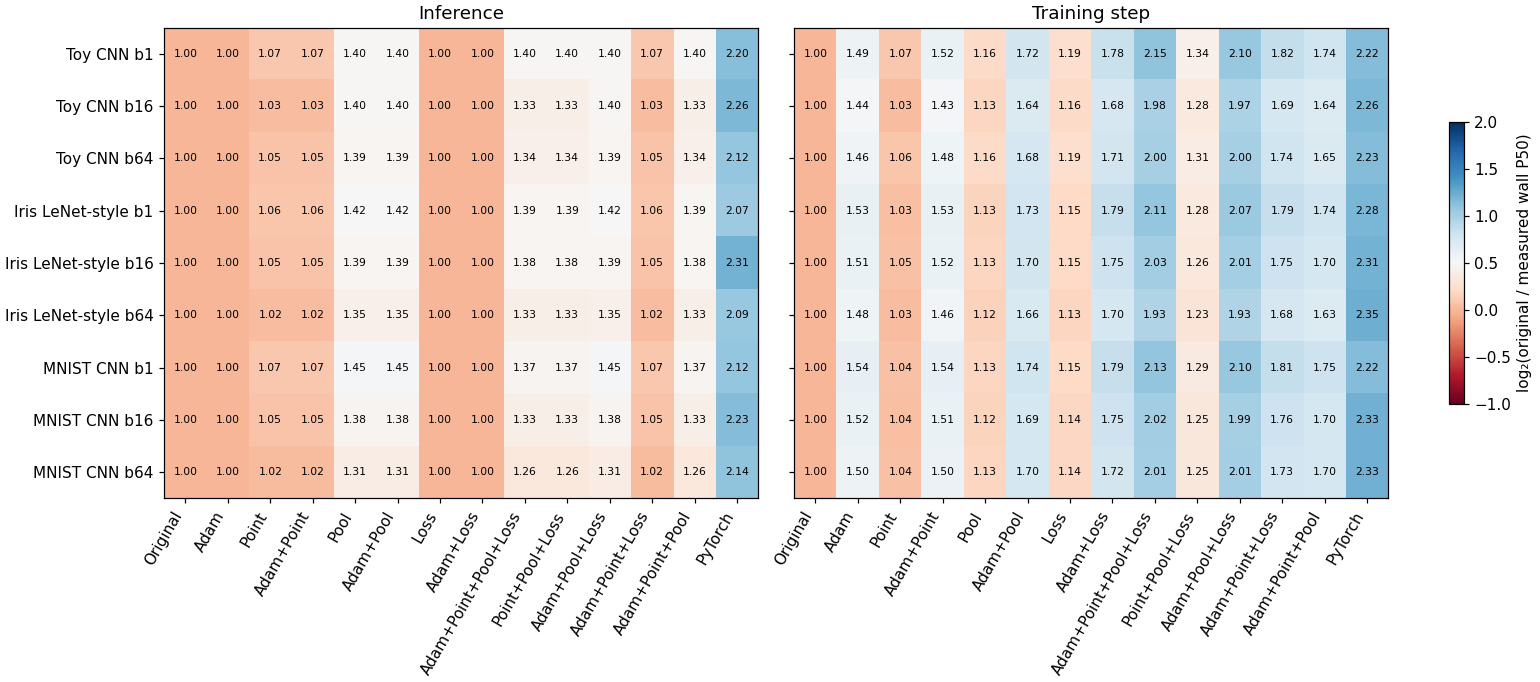

In [13]:
def clone(data, source):
    model = make_model(data, 42)
    for a, b in zip(source.layers, model.layers):
        b.W.data[...] = a.W.data
        b.b.data[...] = a.b.data
    return model


combined = {}
for data in workloads:
    checkpoint = checkpoints[data.name]
    torch_model = TorchCNN(data, checkpoint).cuda()
    for batch in BATCHES:
        x, y = (cp.asarray(a[:batch]) for a in data.train)
        tx, ty = torch.from_numpy(data.train[0][:batch]).cuda(), torch.from_numpy(data.train[1][:batch]).cuda()
        with no_grad(), torch.inference_mode():
            np.testing.assert_allclose(torch_model(tx).cpu().numpy(), cp.asnumpy(checkpoint(x).data),
                                       rtol=5e-4, atol=6e-5)
            # Adam and loss have no inference work. Measure each effective path once.
            inference_variants = list(dict.fromkeys(v & {'Point', 'Pool'} for v in VARIANTS))
            infer_calls = [(lambda v=v: enabled(v), lambda: checkpoint(x)) for v in inference_variants]
            infer_calls.append((nullcontext, lambda: torch_model(tx)))
            measured = measure(infer_calls)
            inference = [measured[inference_variants.index(v & {'Point', 'Pool'})] for v in VARIANTS]
            inference.append(measured[-1])
        train_calls = []
        for features in VARIANTS:
            model = clone(data, checkpoint)
            opt = Adam(lr=0.003, fused='Adam' in features).setup(model)
            train_calls.append((lambda v=features: enabled(v),
                                lambda m=model, o=opt: step(m, o, (x, y))))
        tm = TorchCNN(data, checkpoint).cuda().train()
        topt = torch.optim.Adam(tm.parameters(), lr=0.003)
        def torch_update():
            topt.zero_grad(set_to_none=True)
            loss = nn.functional.cross_entropy(tm(tx), ty)
            loss.backward()
            topt.step()
        train_calls.append((nullcontext, torch_update))
        training = measure(train_calls)
        combined[data.name, batch] = (inference, training)
        print(data.name, batch, 'original / all-on / PyTorch wall P50 ms',
              [[round(v[i]['wall'], 3) for i in (0, VARIANTS.index(ALL), -1)]
               for v in (inference, training)], flush=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), layout='constrained', sharey=True)
for phase, ax in enumerate(axes):
    values = np.array([[row[phase][0]['wall'] / v['wall'] for v in row[phase]]
                       for row in combined.values()])
    image = ax.imshow(np.log2(values), aspect='auto', cmap='RdBu', vmin=-1, vmax=2)
    for i, j in np.ndindex(values.shape):
        ax.text(j, i, f'{values[i,j]:.2f}', ha='center', va='center', fontsize=7)
    ax.set_xticks(np.arange(len(VARIANTS) + 1), [label(v) for v in VARIANTS] + ['PyTorch'],
                  rotation=60, ha='right')
    ax.set(title=('Inference', 'Training step')[phase])
axes[0].set_yticks(np.arange(len(combined)), [f'{n} b{b}' for n,b in combined])
fig.colorbar(image, ax=axes, label='log₂(original / measured wall P50)', shrink=0.6)
plt.show()

In [14]:
import os

reference_root = os.environ.get('DEZERO_REFERENCE')
if reference_root:
    sys.path.insert(0, reference_root)
    # The reference uses the removed NumPy alias in a transform default.
    with patch.object(np, "int", int, create=True):
        import dezero
        import dezero.functions as DF
        from dezero.models import MLP as DeZeroMLP
        from dezero.optimizers import SGD as DeZeroSGD
    from mydezero.optimizers import SGD

    native_results = {}
    for batch in BATCHES:
        x = cp.asarray(rand.standard_normal((batch, 64), dtype=np.float32))
        target = cp.asarray(rand.integers(8, size=batch, dtype=np.int64))
        native = DeZeroMLP((128, 8), activation=DF.relu)
        current = MLP((128, 8), activation=F.relu)
        native.to_gpu()
        current.to_gpu()
        native(x)
        current(x)
        for a, b in zip(native.layers, current.layers):
            weight = cp.asarray(rand.standard_normal(a.W.shape, dtype=np.float32)) * np.float32(0.1)
            a.W.data, b.W.data = weight.copy(), weight.copy()
            a.b.data = cp.zeros(a.b.shape, dtype=cp.float32)
            b.b.data = cp.zeros(b.b.shape, dtype=cp.float32)
        cp.testing.assert_allclose(native(x).data, current(x).data, rtol=1e-5, atol=1e-6)
        no, co = DeZeroSGD(lr=0.01).setup(native), SGD(lr=0.01).setup(current)
        def native_step():
            native.cleargrads()
            loss = DF.softmax_cross_entropy(native(x), target)
            loss.backward()
            no.update()
        def current_step():
            current.cleargrads()
            loss = F.softmax_cross_entropy(current(x), target)
            loss.backward()
            co.update()
        native_step()
        with enabled(ALL):
            current_step()
        for a, b in zip(native.layers, current.layers):
            cp.testing.assert_allclose(a.W.grad.data, b.W.grad.data, rtol=4e-4, atol=3e-6)
            cp.testing.assert_allclose(a.W.data, b.W.data, rtol=4e-4, atol=3e-6)
        native_results[batch] = measure([(nullcontext, native_step), (lambda: enabled(ALL), current_step)])
        print('Native DeZero / MyDeZero, aligned SGD MLP, batch', batch,
              [round(v['wall'], 3) for v in native_results[batch]])
else:
    print('Native reference skipped. Set DEZERO_REFERENCE to a compatible DeZero checkout root.')

Native DeZero / MyDeZero, aligned SGD MLP, batch 1 [0.92, 0.484]
Native DeZero / MyDeZero, aligned SGD MLP, batch 16 [0.913, 0.499]
Native DeZero / MyDeZero, aligned SGD MLP, batch 64 [0.911, 0.523]


4 equal tensors, standard / per-tensor / multi-tensor wall P50 ms [0.506, 0.094, 0.064]
64 equal tensors, standard / per-tensor / multi-tensor wall P50 ms [7.71, 1.125, 0.118]


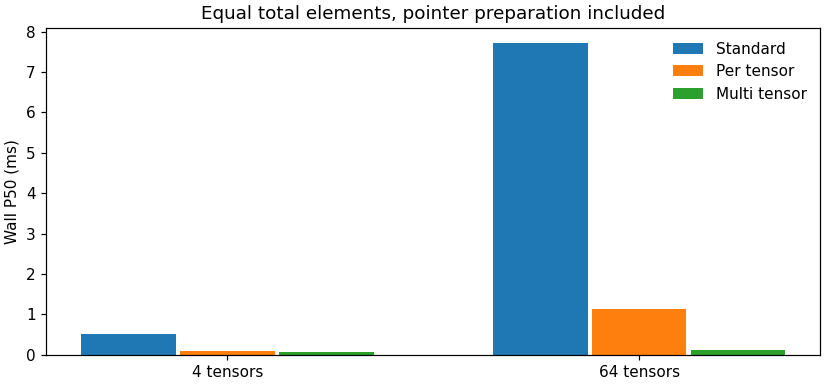

In [15]:
from gpu_multi_adam_probe import EqualSizeAdam

multi_results = {}
for count in (4, 64):
    size = 16384 // count
    variants = []
    for mode in ('Standard', 'Per tensor', 'Multi tensor'):
        layer = Layer()
        params = []
        for i in range(count):
            param = Parameter(cp.ones(size, dtype=cp.float32))
            param.grad = Variable(cp.full(size, 0.001, dtype=cp.float32))
            setattr(layer, f'p{i}', param)
            params.append(param)
        opt = (EqualSizeAdam(params) if mode == 'Multi tensor'
               else Adam(lr=0.003, fused=mode == 'Per tensor').setup(layer))
        variants.append((params, opt))
    for _ in range(12):
        for params, opt in variants:
            opt.update()
    for i in range(count):
        cp.testing.assert_allclose(variants[2][0][i].data, variants[1][0][i].data, atol=2e-6, rtol=2e-6)
    calls = [(nullcontext, opt.update) for _, opt in variants]
    multi_results[count] = measure(calls)
    print(count, 'equal tensors, standard / per-tensor / multi-tensor wall P50 ms',
          [round(v['wall'], 3) for v in multi_results[count]])
fig, ax = plt.subplots(figsize=(7.5, 3.5), layout='constrained')
for i, name in enumerate(('Standard', 'Per tensor', 'Multi tensor')):
    ax.bar(np.arange(2) + (i - 1) * 0.24,
           [multi_results[count][i]['wall'] for count in (4, 64)], width=0.23, label=name)
ax.set_xticks((0, 1), ('4 tensors', '64 tensors'))
ax.set(ylabel='Wall P50 (ms)', title='Equal total elements, pointer preparation included')
ax.legend(frameon=False)
plt.show()

Toy CNN full CNN graph unavailable: calling cuBLAS API during stream capture is currently unsupported
Toy CNN pooling + ReLU capture ms 0.37 eager / graph wall P50 [0.042, 0.016]
Iris LeNet-style full CNN graph unavailable: calling cuBLAS API during stream capture is currently unsupported
Iris LeNet-style pooling + ReLU capture ms 0.262 eager / graph wall P50 [0.042, 0.016]
MNIST CNN full CNN graph unavailable: calling cuBLAS API during stream capture is currently unsupported
MNIST CNN pooling + ReLU capture ms 0.261 eager / graph wall P50 [0.041, 0.016]
Prepared pageable / pinned transfer wall P50 ms [0.02544999999987141, 0.021499999999896602]
Pinned buffer preparation is outside this transfer-only comparison.


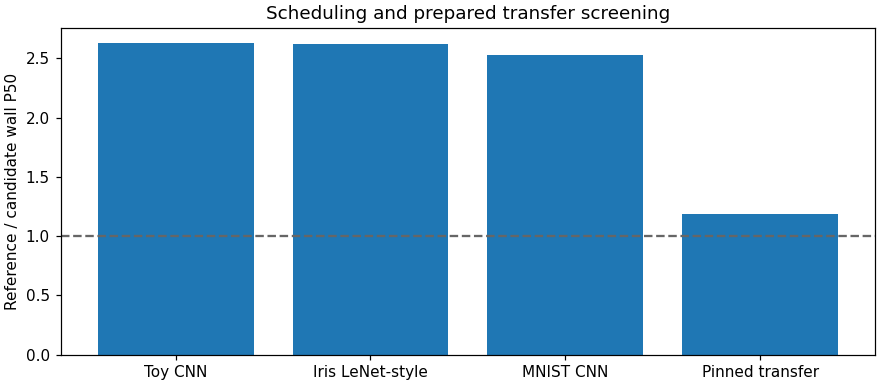

In [16]:
graph_results = {}
for data in workloads:
    model = checkpoints[data.name]
    source = cp.asarray(data.train[0][:16])
    x = source.copy()
    cp.cuda.runtime.deviceSynchronize()
    stream = cp.cuda.Stream(non_blocking=True)
    with enabled(ALL), no_grad():
        with stream:
            for _ in range(4):
                model(x)
        stream.synchronize()
        started = perf_counter()
        with stream:
            stream.begin_capture()
            try:
                output = model(x)
            except NotImplementedError as error:
                stream.end_capture()
                print(data.name, 'full CNN graph unavailable:', str(error))
                graph_call = lambda: F.relu(FC.pooling(x, 2, stride=2))
                for _ in range(3):
                    graph_call()
                stream.synchronize()
                stream.begin_capture()
                output = graph_call()
                graph = stream.end_capture()
                graph_scope = 'pooling + ReLU'
            else:
                graph = stream.end_capture()
                graph_call = lambda: model(x)
                graph_scope = 'full inference'
        setup_ms = (perf_counter() - started) * 1000
        for scale in (0.5, 1.0, 1.5):
            with stream:
                cp.multiply(source, np.float32(scale), out=x)
                graph.launch(stream)
            stream.synchronize()
            cp.testing.assert_allclose(output.data, graph_call().data, rtol=4e-4, atol=5e-5)
        values = measure([(nullcontext, graph_call),
                          (nullcontext, lambda: graph.launch(stream))])
        graph_results[data.name] = values
        print(data.name, graph_scope, 'capture ms', round(setup_ms, 3), 'eager / graph wall P50',
              [round(v['wall'], 3) for v in values])

host = np.random.default_rng(8).standard_normal((64, 1, 28, 28), dtype=np.float32)
pinned = cp.cuda.alloc_pinned_memory(host.nbytes)
pinned_array = np.frombuffer(pinned, dtype=np.float32, count=host.size).reshape(host.shape)
pinned_array[...] = host
destination = cp.empty(host.shape, dtype=cp.float32)
transfer_stream = cp.cuda.Stream(non_blocking=True)
def synchronous_transfer():
    destination.set(host)
def asynchronous_transfer():
    destination.set(pinned_array, stream=transfer_stream)
transfer_results = measure([(nullcontext, synchronous_transfer), (nullcontext, asynchronous_transfer)])
cp.testing.assert_array_equal(destination, cp.asarray(host))
print('Prepared pageable / pinned transfer wall P50 ms', [v['wall'] for v in transfer_results])
print('Pinned buffer preparation is outside this transfer-only comparison.')
fig, ax = plt.subplots(figsize=(8, 3.5), layout='constrained')
ax.bar([*graph_results, 'Pinned transfer'],
       [v[0]['wall'] / v[1]['wall'] for v in graph_results.values()] +
       [transfer_results[0]['wall'] / transfer_results[1]['wall']])
ax.axhline(1, color='0.4', linestyle='--')
ax.set(ylabel='Reference / candidate wall P50', title='Scheduling and prepared transfer screening')
plt.show()

## Application inference with official weights

Set `MYDEZERO_WEIGHTS_DIR` to a directory containing compatible `resnet50.npz`
and `vgg16.npz` archives. By default, look under the repository's
`models/dezero-official` directory. Run the same model and checkpoint at batches
1 and 4 with original and optimized GPU operators. Inputs are fixed synthetic
FP32 images. This validates logits and latency, with classification quality
covered by the trained dataset experiments above. Weight loading is untimed.


ResNet50 1 wall P50/P95 ms [(11.406, 13.12), (11.615, 12.989)] speedup 0.98
ResNet50 4 wall P50/P95 ms [(21.349, 25.483), (22.222, 26.377)] speedup 0.96
VGG16 1 wall P50/P95 ms [(9.872, 10.457), (9.383, 9.906)] speedup 1.05
VGG16 4 wall P50/P95 ms [(41.428, 44.461), (39.265, 42.2)] speedup 1.06


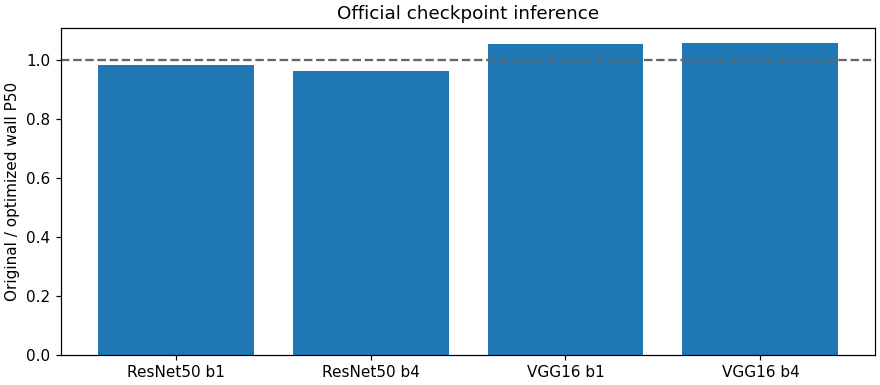

In [17]:
from mydezero.models import ResNet50, VGG16

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists())
weights_dir = Path(os.environ.get('MYDEZERO_WEIGHTS_DIR', root / 'models/dezero-official'))
application_results = {}
for model_class, filename in ((ResNet50, 'resnet50.npz'), (VGG16, 'vgg16.npz')):
    archive = weights_dir / filename
    if not archive.is_file():
        print(filename, 'skipped: compatible archive unavailable')
        continue
    cp.get_default_memory_pool().free_all_blocks()
    application_model = model_class()
    application_model.load_weights(archive)
    application_model.to_gpu()
    assert all(p.dtype == np.float32 for p in application_model.params())
    for batch in (1, 4):
        x = cp.asarray(np.random.default_rng(39).standard_normal((batch, 3, 224, 224), dtype=np.float32))
        with no_grad(), test_mode():
            with enabled(BASE):
                expected = application_model(x).data
            with enabled(ALL):
                actual = application_model(x).data
            np.testing.assert_allclose(cp.asnumpy(actual), cp.asnumpy(expected), rtol=5e-4, atol=1e-4)
            cp.testing.assert_array_equal(actual.argmax(axis=1), expected.argmax(axis=1))
            values = measure([(lambda: enabled(BASE), lambda: application_model(x)),
                              (lambda: enabled(ALL), lambda: application_model(x))])
        application_results[model_class.__name__, batch] = values
        print(model_class.__name__, batch, 'wall P50/P95 ms',
              [(round(v['wall'], 3), round(v['p95'], 3)) for v in values],
              'speedup', round(values[0]['wall'] / values[1]['wall'], 2), flush=True)
    del application_model

if application_results:
    fig, ax = plt.subplots(figsize=(8, 3.5), layout='constrained')
    ax.bar([f'{name} b{batch}' for name, batch in application_results],
           [v[0]['wall'] / v[1]['wall'] for v in application_results.values()])
    ax.axhline(1, color='0.4', linestyle='--')
    ax.set(ylabel='Original / optimized wall P50', title='Official checkpoint inference')
    plt.show()


('Toy CNN', 1) Inference speedup 1.40, paired 95% interval [1.36, 1.44], optimized/PyTorch wall ratio 1.57, samples/s 2170
('Toy CNN', 16) Inference speedup 1.33, paired 95% interval [1.31, 1.37], optimized/PyTorch wall ratio 1.69, samples/s 31599
('Toy CNN', 64) Inference speedup 1.34, paired 95% interval [1.30, 1.42], optimized/PyTorch wall ratio 1.58, samples/s 116438
('Iris LeNet-style', 1) Inference speedup 1.39, paired 95% interval [1.34, 1.41], optimized/PyTorch wall ratio 1.49, samples/s 1964
('Iris LeNet-style', 16) Inference speedup 1.38, paired 95% interval [1.30, 1.40], optimized/PyTorch wall ratio 1.67, samples/s 29428
('Iris LeNet-style', 64) Inference speedup 1.33, paired 95% interval [1.29, 1.37], optimized/PyTorch wall ratio 1.57, samples/s 116406
('MNIST CNN', 1) Inference speedup 1.37, paired 95% interval [1.32, 1.42], optimized/PyTorch wall ratio 1.54, samples/s 1934
('MNIST CNN', 16) Inference speedup 1.33, paired 95% interval [1.32, 1.35], optimized/PyTorch wall r

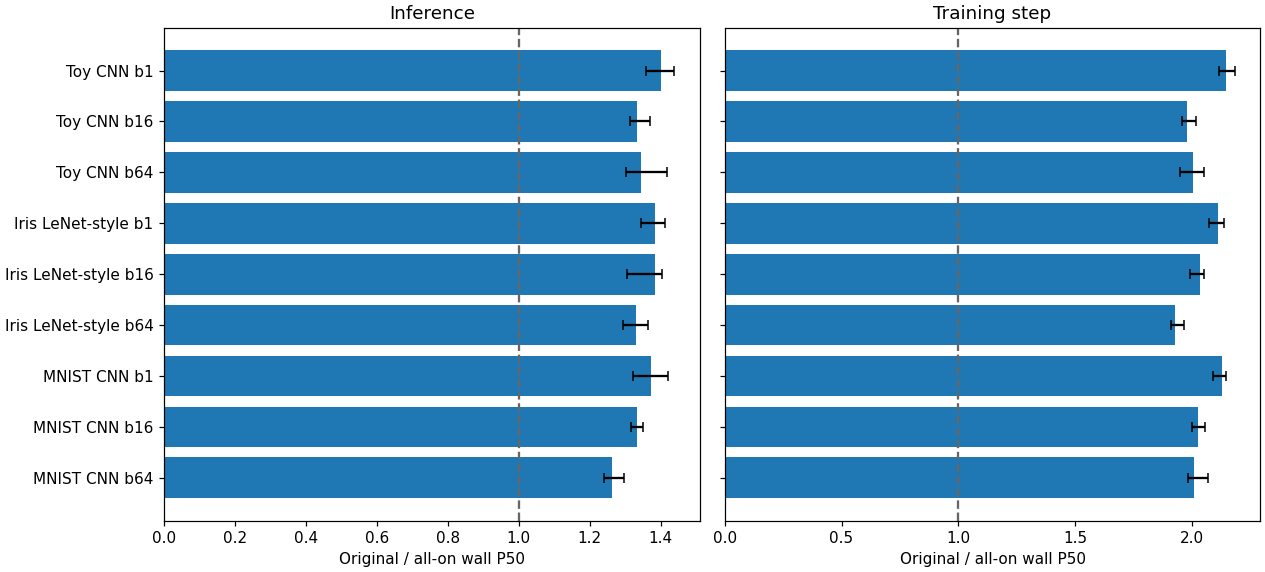

In [18]:
summary_rng = np.random.default_rng(49)
summary_ranges = {}
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.2), layout='constrained', sharey=True)
for phase, ax in enumerate(axes):
    ratios, intervals = [], []
    for key, values in combined.items():
        original = values[phase][0]
        optimized = values[phase][VARIANTS.index(ALL)]
        left = np.asarray(original['rounds']).reshape(RUNS, ROUNDS)
        right = np.asarray(optimized['rounds']).reshape(RUNS, ROUNDS)
        runs = summary_rng.integers(RUNS, size=(2000, RUNS, 1))
        rounds = summary_rng.integers(ROUNDS, size=(2000, RUNS, ROUNDS))
        bootstrap = np.median(left[runs, rounds], axis=(1, 2)) / np.median(right[runs, rounds], axis=(1, 2))
        interval = np.percentile(bootstrap, (2.5, 97.5))
        ratio = original['wall'] / optimized['wall']
        ratios.append(ratio)
        intervals.append(interval)
        print(key, ('Inference', 'Training')[phase],
              f"speedup {ratio:.2f}, paired 95% interval [{interval[0]:.2f}, {interval[1]:.2f}], "
              f"optimized/PyTorch wall ratio {optimized['wall'] / values[phase][-1]['wall']:.2f}, "
              f"samples/s {key[1] * 1000 / optimized['wall']:.0f}")
    intervals = np.asarray(intervals)
    errors = np.maximum(0, np.stack((np.asarray(ratios) - intervals[:, 0], intervals[:, 1] - ratios)))
    ax.barh(np.arange(len(ratios)), ratios, xerr=errors, capsize=3)
    ax.axvline(1, color='0.4', linestyle='--')
    ax.set(title=('Inference', 'Training step')[phase], xlabel='Original / all-on wall P50')
    summary_ranges[phase] = min(ratios), max(ratios)
axes[0].set_yticks(np.arange(len(combined)), [f'{name} b{batch}' for name, batch in combined])
axes[0].invert_yaxis()
plt.show()
print('Speedup ranges', summary_ranges)
print('Intervals resample paired rounds within runs. They describe repeat blocks in this process.')


## Acceptance boundaries

The all-on model suite measures pointwise convolution, direct pooling, fused
cross entropy and per-tensor Adam. cuDNN and CUDA Graph results are feasibility
probes outside the all-on training implementation. Captured training requires a
separate state design. The equal-size multi-tensor Adam prototype remains an
example. The transfer screen measures prepared buffers
and establishes no complete-epoch prefetch benefit.

The resident-data training timings exclude scalar logging and transfers.
CUDA Event values on the default stream cannot describe work launched on the
separate graph or transfer stream. Use synchronized wall results for those
comparisons. Profiler kernel counts and hardware counters require compatible
Nsight tooling and are unavailable when the installed tools cannot collect them.
The listed datasets and model subsets establish the scope of quality results.

In the saved run, VGG16 improved about 5–6% and ResNet50 regressed about 2–4%
at batches 1 and 4. The Toy/Iris/MNIST all-on suite improved inference
1.26–1.40× and training 1.93–2.15×. This includes existing Adam fusion.
Optimized training latency remained 1.03–1.22× PyTorch eager.

The timing protocol uses three repeat blocks in one process. The intervals
resample repeat blocks and their paired round medians. They do not estimate
cross-machine or cross-process reproducibility. Fresh-process replication,
CIFAR-10 training, portable cuDNN integration, generalized multi-tensor Adam,
captured training and complete-epoch prefetch remain acceptance follow-ups.

The native-DeZero MLP check uses aligned SGD and a temporary import-time
`np.int` compatibility alias for that reference checkout. Package sources are
untouched. All benchmark tensors are explicitly FP32.


## Large-model follow-up

ResNet50's initial 1x1 path used batched GEMM and regressed at several later
stage shapes. Flattening batch and pixels produces a single GEMM. A separate
problem widened global-average-pooling outputs and BatchNorm gradients to
FP64 through integer count arrays. Internal counts now use at least FP32 precision.

The following experiment measures ResNet50 at batches 1, 4 and 16 and VGG16 at
batches 1, 4 and 8 using official shared weights and fixed 224x224 inputs.
It records inference and complete synthetic training steps, including Adam.
Training dropout is seeded equally within MyDeZero comparisons. PyTorch uses
the same architecture, including original-MSRA ResNet strides and VGG dropout.
All comparisons disable TF32. Inference variants alternate on one checkpoint.
Training variants use independent fresh checkpoints, with their order rotated
between three separate Python processes.

The layout follow-up supports the official VGG dense weights' Fortran order.
It packs gradients and updates physical flat views with the fused Adam kernel.
The `Flat GEMM` and `cuDNN` controls retain the earlier C-only Adam eligibility
rule. `Fortran Adam` and `cuDNN+Fortran Adam` add the layout correction.

The FP32 reference retains original operators and standard Adam. Flat GEMM adds
the accepted GPU optimizations. cuDNN adds an opt-in experimental backend. A
cuDNN training case is rejected when the first-step gradient relative L2 error
exceeds 0.005 against the FP32 reference. Rejected cells receive no training
speedup. This gate is separate from future dataset-level quality acceptance.

Set `RUN_LARGE_MODEL_VALIDATION=True` to regenerate the ignored result files.
They include raw timings, logits/gradient dtypes and first-step numerical checks.
These tests cover resident GPU compute throughput. A dataset's total size
affects the number of steps and does not increase the work in a fixed batch.


ResNet50 1 FP32 reference inference P50/P95 11.260/12.835 ms, speedup 1.04, process range [1.00,1.04], samples/s 89
ResNet50 4 FP32 reference inference P50/P95 22.414/24.343 ms, speedup 1.07, process range [1.06,1.07], samples/s 178
ResNet50 16 FP32 reference inference P50/P95 63.138/73.868 ms, speedup 1.02, process range [1.01,1.02], samples/s 253
VGG16 1 FP32 reference inference P50/P95 13.119/14.833 ms, speedup 1.01, process range [1.00,1.01], samples/s 76
VGG16 4 FP32 reference inference P50/P95 41.531/52.382 ms, speedup 1.01, process range [1.00,1.01], samples/s 96
VGG16 8 FP32 reference inference P50/P95 80.395/86.889 ms, speedup 1.01, process range [1.00,1.01], samples/s 100
ResNet50 1 Flat GEMM inference P50/P95 10.465/11.831 ms, speedup 1.12, process range [1.11,1.13], samples/s 96
ResNet50 4 Flat GEMM inference P50/P95 21.799/23.763 ms, speedup 1.10, process range [1.08,1.10], samples/s 183
ResNet50 16 Flat GEMM inference P50/P95 61.662/72.366 ms, speedup 1.04, process range 

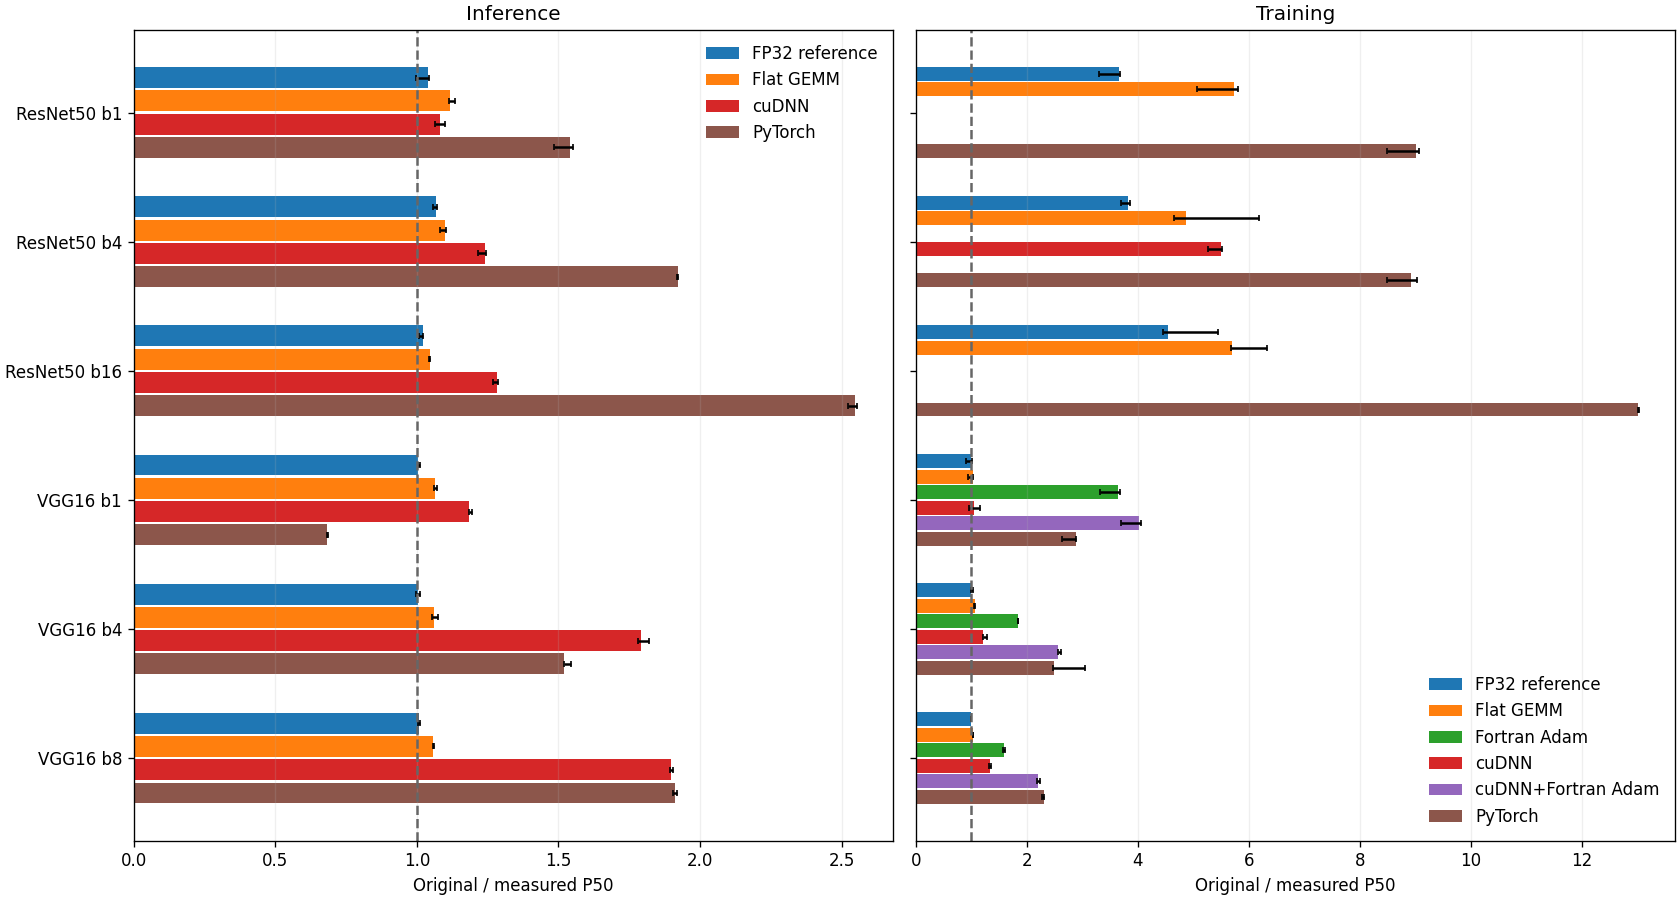

In [19]:
import json
import os
import subprocess

RUN_LARGE_MODEL_VALIDATION = False
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists())
large_results_dir = project_root / 'draft' / 'gpu-large-results'
large_results_dir.mkdir(parents=True, exist_ok=True)
large_paths = [large_results_dir / f'process-{i}.json' for i in range(3)]
layout_paths = [large_results_dir / f'layout-{i}.json' for i in range(3)]
large_weights = Path(os.environ.get('MYDEZERO_WEIGHTS_DIR', project_root / 'models/dezero-official'))
if RUN_LARGE_MODEL_VALIDATION:
    helper = project_root / 'examples/neural_network/gpu_large_workloads.py'
    for i, result_path in enumerate(large_paths):
        subprocess.run([sys.executable, str(helper), '--weights', str(large_weights),
                        '--output', str(result_path), '--process', str(i)], check=True,
                       env=dict(os.environ, NVIDIA_TF32_OVERRIDE='0'))
    for i, result_path in enumerate(layout_paths):
        subprocess.run([sys.executable, str(helper), '--weights', str(large_weights),
                        '--output', str(result_path), '--process', str(i), '--layout-followup'], check=True,
                       env=dict(os.environ, NVIDIA_TF32_OVERRIDE='0'))

if not all(p.is_file() for p in large_paths):
    print('Large-model results unavailable. Configure weights/cuDNN and enable RUN_LARGE_MODEL_VALIDATION.')
else:
    large_rows = [row for result_path in large_paths for row in json.loads(result_path.read_text())]
    if all(p.is_file() for p in layout_paths):
        large_rows.extend(row for p in layout_paths for row in json.loads(p.read_text()) if row['mode'] != 'PyTorch')
    model_batches = [('ResNet50', 1), ('ResNet50', 4), ('ResNet50', 16),
                     ('VGG16', 1), ('VGG16', 4), ('VGG16', 8)]
    modes = ('Original', 'FP32 reference', 'Flat GEMM', 'Fortran Adam', 'cuDNN', 'cuDNN+Fortran Adam', 'PyTorch')
    fig, axes = plt.subplots(1, 2, figsize=(14, 7.5), layout='constrained', sharey=True)
    for phase, ax in zip(('inference', 'training'), axes):
        phase_modes = ('FP32 reference', 'Flat GEMM', 'cuDNN', 'PyTorch') if phase == 'inference' else modes[1:]
        bar_height = 0.72 / len(phase_modes)
        for index, name in enumerate(phase_modes):
            speeds, lows, highs = [], [], []
            for model_name, batch in model_batches:
                ref = sorted([r for r in large_rows if r['model'] == model_name and r['batch'] == batch
                              and r['mode'] == 'Original'], key=lambda r: r['process'])
                # Optimizer layout has no inference work. Reuse the paired forward measurement.
                effective_name = ({'Fortran Adam': 'Flat GEMM', 'cuDNN+Fortran Adam': 'cuDNN'}.get(name, name)
                                  if phase == 'inference' else name)
                values = sorted([r for r in large_rows if r['model'] == model_name and r['batch'] == batch
                                 and r['mode'] == effective_name], key=lambda r: r['process'])
                if len(values) != 3 or any(v[phase] is None for v in values):
                    speeds.append(np.nan)
                    lows.append(0)
                    highs.append(0)
                    if phase == 'training' and len(values) == 3:
                        print(model_name, batch, name, 'training rejected',
                              [round(v['gradient_relative_l2'], 6) for v in values])
                    continue
                ratios = np.array([a[phase]['p50'] / b[phase]['p50'] for a,b in zip(ref, values)])
                speed = float(np.median(ratios))
                speeds.append(speed)
                lows.append(speed - ratios.min())
                highs.append(ratios.max() - speed)
                p50 = float(np.median([v[phase]['p50'] for v in values]))
                p95 = float(np.median([v[phase]['p95'] for v in values]))
                print(model_name, batch, name, phase, f'P50/P95 {p50:.3f}/{p95:.3f} ms, '
                      f'speedup {speed:.2f}, process range [{ratios.min():.2f},{ratios.max():.2f}], '
                      f'samples/s {batch * 1000 / p50:.0f}')
            position = np.arange(len(model_batches)) + (index - (len(phase_modes) - 1) / 2) * bar_height
            ax.barh(position, speeds, height=bar_height * 0.9, xerr=np.array([lows, highs]), capsize=2, color=f'C{modes.index(name) - 1}', label=name)
        ax.axvline(1, color='0.4', linestyle='--')
        ax.set(title=phase.title(), xlabel='Original / measured P50')
        ax.grid(axis='x', alpha=0.2)
        ax.legend(frameon=False)
    axes[0].set_yticks(np.arange(len(model_batches)), [f'{m} b{b}' for m,b in model_batches])
    axes[0].invert_yaxis()
    plt.show()
    print('Error bars show the range over three fresh processes. Missing cuDNN training bars are rejected cases. Fortran-only training is measured for VGG16.')
    for model_name, batch in model_batches:
        values = [r for r in large_rows if r['model'] == model_name and r['batch'] == batch
                  and r['mode'] in ('Original', 'FP32 reference') and r['process'] == 0]
        print(model_name, batch, 'logit and gradient dtypes',
              [(v['mode'], v['logit_dtype'], v['gradient_dtypes']) for v in values])


## Large-model decisions

The default path removes the observed ResNet inference regression. At batch 16,
ResNet50 training takes 243.56 ms versus 1386.32 ms for original behavior and
305.53 ms for the corrected FP32 reference. The large historical-baseline gain
includes removal of unintended FP64 work. VGG16 batch-8 training takes 232.23 ms
with layout-aware Adam, versus 354.61 ms with the earlier C-only fusion rule.

Experimental cuDNN plus layout-aware Adam reduces VGG16 batch-8 training to
165.83 ms, compared with matched PyTorch eager at 159.28 ms. VGG16 batch-8
inference takes 42.73 ms with cuDNN versus 81.08 ms for original behavior.
ResNet50 batch-16 inference takes 50.18 ms with cuDNN versus 64.43 ms originally,
while matched PyTorch takes 25.26 ms. Substantial ResNet execution work remains.

The cuDNN ResNet training gate rejects batches 1 and 16 with first-gradient
relative-L2 errors of 0.008288 and 0.005555, above the 0.005 threshold. The backend
stays opt-in and disabled by default. These configurations have no accepted
training speedup. Passed first-step checks and the 326-test regression suite
support operator correctness within the tested tolerances. Large-dataset
convergence, held-out quality and complete-epoch pipeline performance remain
unmeasured in this follow-up.
